Produces Fig. 2(a)–(c) of the paper.

In [1]:
import matplotlib.pyplot as plt

import matplotlib as mpl
import scienceplots

mpl.rcParams.update(mpl.rcParamsDefault)

plt.style.use(["science", "bright"])
plt.rcParams.update(
    {
        "font.family": "serif",
        "font.serif": ["Times"],
        "font.size": 14.8,
        "axes.labelsize": 16.9,
        "figure.dpi": "600",
        # turn off LaTeX
        "text.usetex": False,
    }
)

colors = ["#0072B2", "#D55E00", "#CC79A7", "#F0E442"]
line_styles = ["-", "--", "-.", ":"]

Running SGD...
Running Decomposed Dynamics (exact drift)...
Running SGD...
Running Decomposed Dynamics (exact drift)...
Running SGD...
Running Decomposed Dynamics (exact drift)...


100%|██████████| 10000/10000 [03:07<00:00, 53.32it/s]


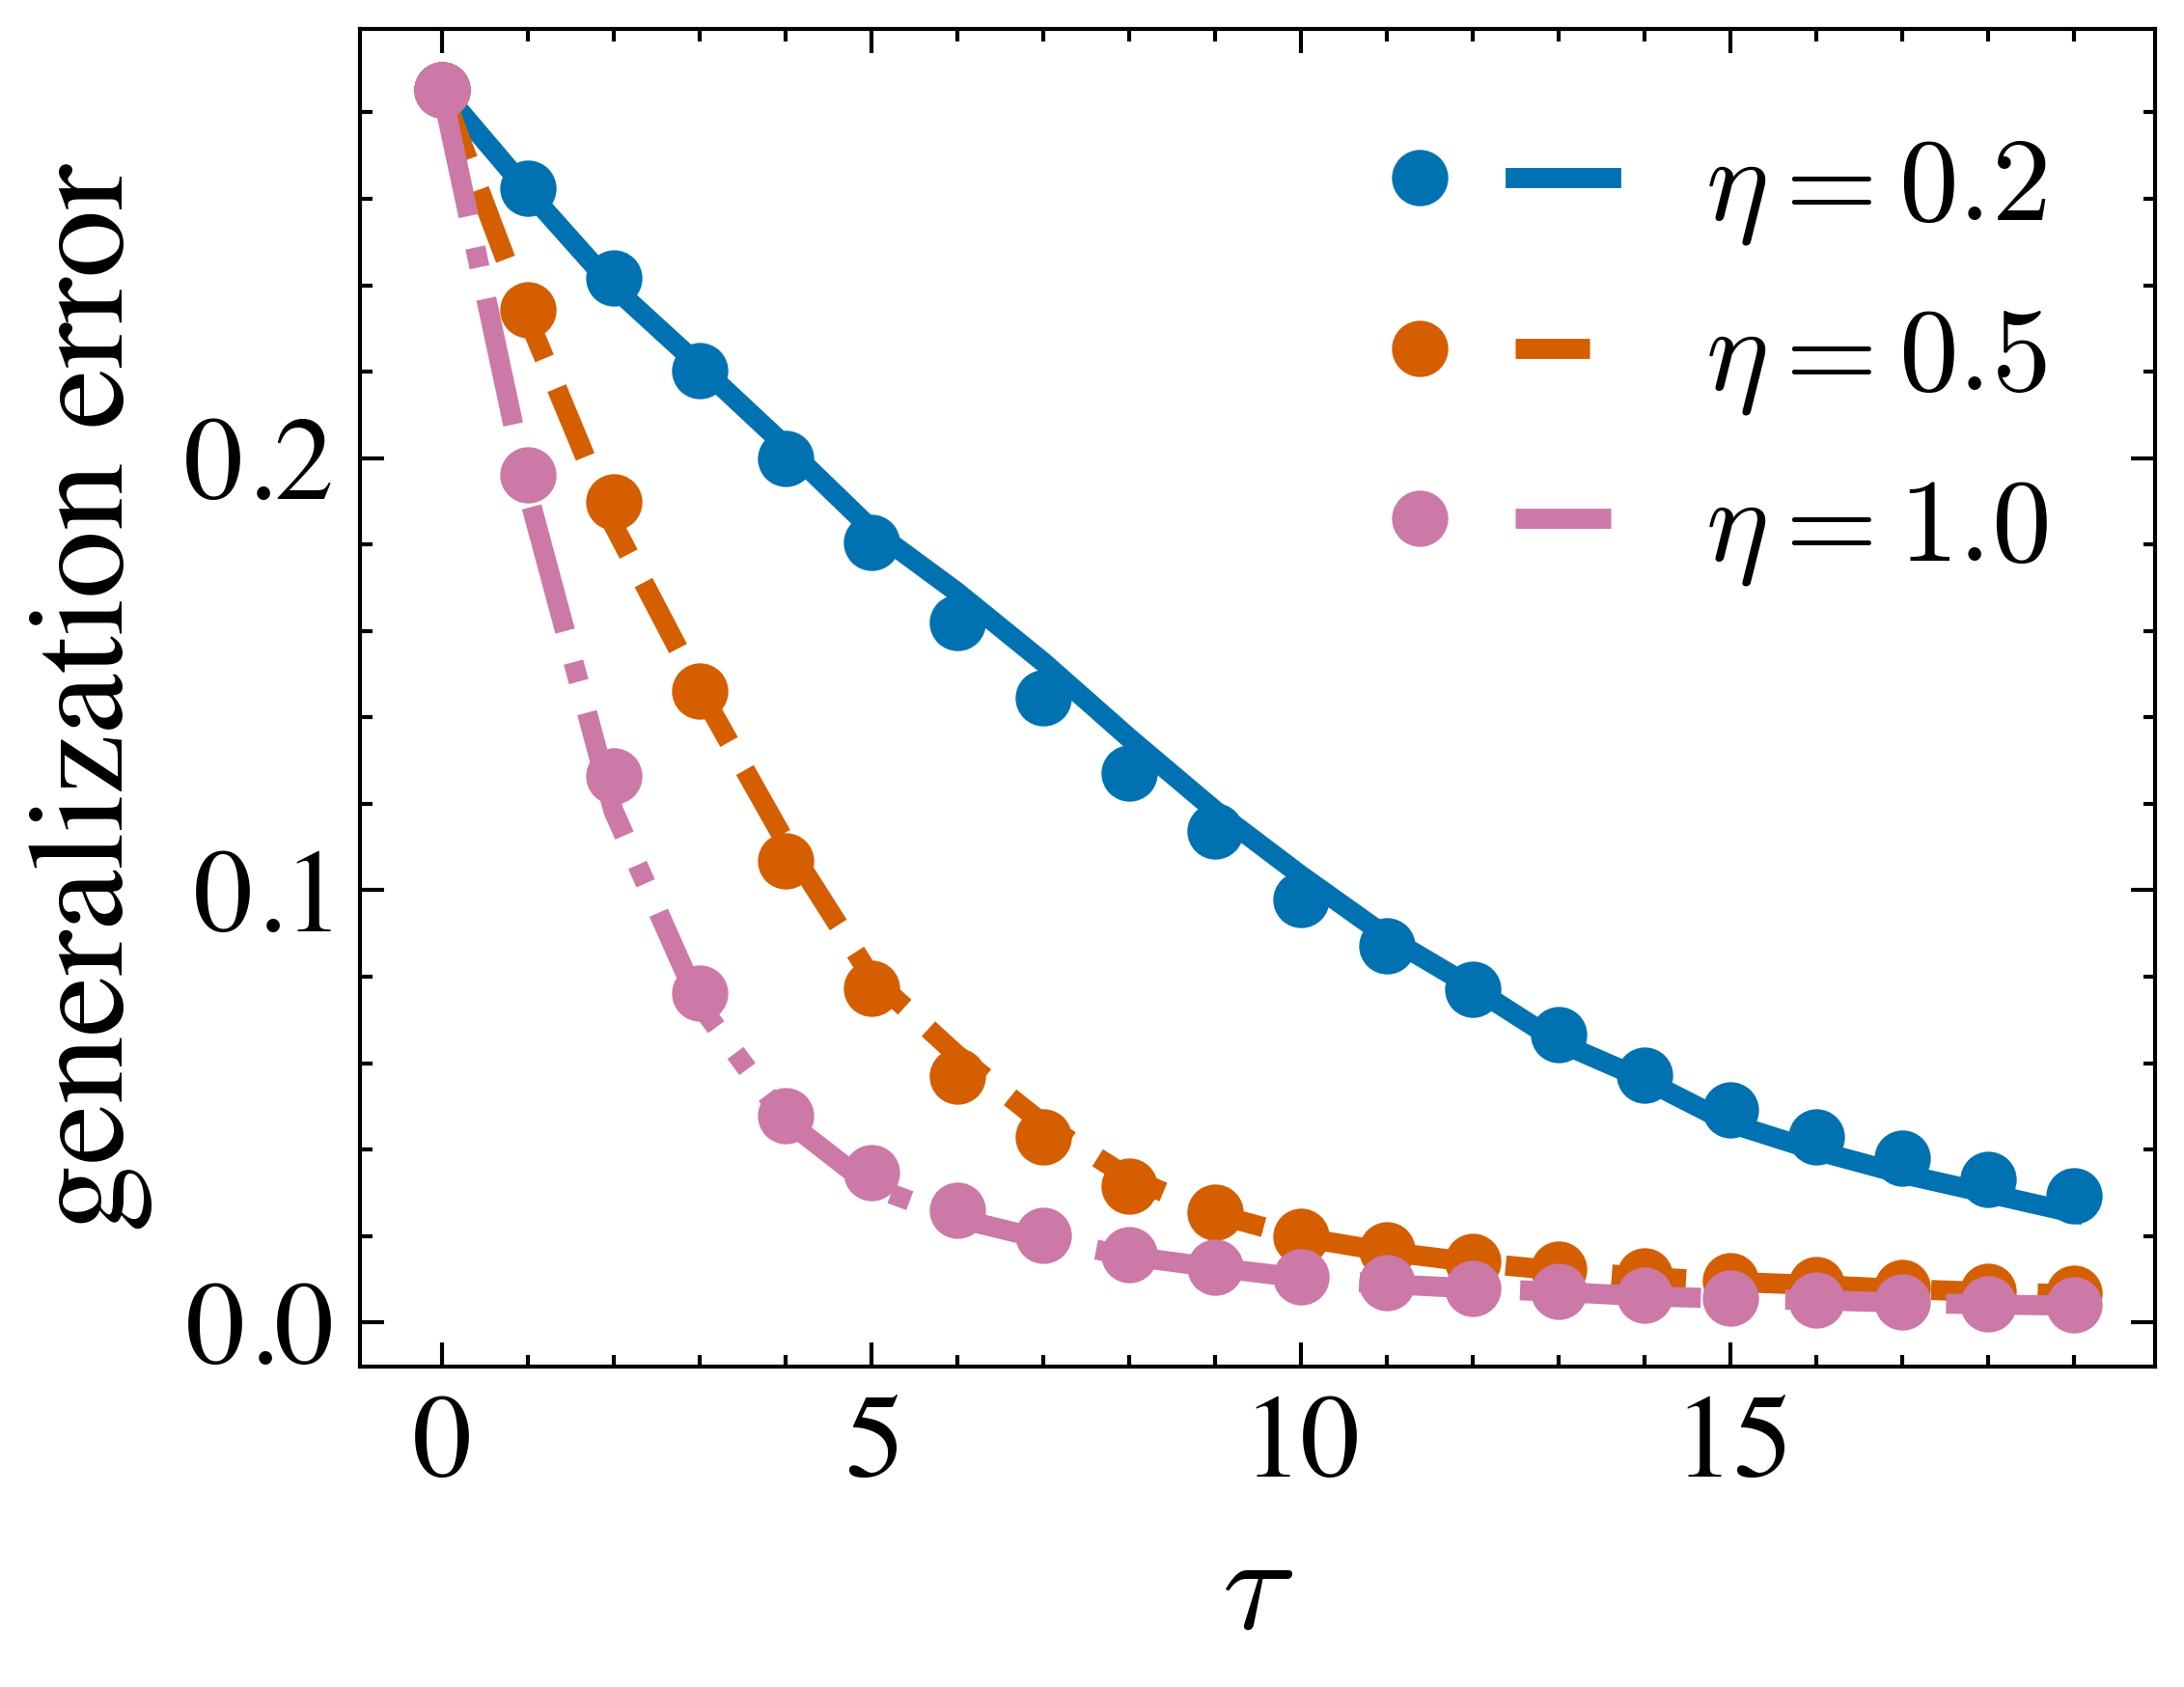

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.legend_handler import HandlerTuple
from tqdm import tqdm

# ---------------------------------------------------------
# 1. Setup
# ---------------------------------------------------------
n = 500
alpha = 1.0
k = int(alpha * n)
tau = 20.0
steps = int(tau * n)

def sigma(x):
    return np.maximum(x, 0)


def sigma_prime(x):
    return (x > 0).astype(float)


def teacher_func(z):
    return sigma(z)  # ReLU teacher


eta_values = [0.2, 0.5, 1.0]

sgd_plots = [None for _ in range(len(eta_values))]
equivalent_plots = [None for _ in range(len(eta_values))]

plt.figure(figsize=(4, 3))

for i,eta in enumerate(eta_values):
    lr_f = lr_a = eta / k

    rng = np.random.default_rng(42)
    xi = rng.normal(0, 1, n)
    xi /= np.linalg.norm(xi)
    F_init = rng.normal(0, 1 / np.sqrt(n), (k, n))
    a_init = rng.normal(0, 1, k)
    # ---------------------------------------------------------
    # Test set (fixed)
    # ---------------------------------------------------------
    test_size = 5000
    z0_test = rng.normal(0, 1, test_size)
    g_test = rng.normal(0, 1, (test_size, n))
    g_test -= np.outer(g_test @ xi, xi)  # project off xi
    x_test = np.outer(z0_test, xi) + g_test
    y_test = teacher_func(z0_test)

    def compute_loss_full(F, a):
        h = x_test @ F.T
        y_hat = (sigma(h) @ a) / k
        return 0.5 * np.mean((y_hat - y_test) ** 2)

    # ---------------------------------------------------------
    # 2. Run SGD (reference)
    # ---------------------------------------------------------
    print("Running SGD...")
    F_sgd = F_init.copy()
    a_sgd = a_init.copy()
    loss_sgd = []

    for t in tqdm(range(steps)):
        z0 = rng.normal()
        g = rng.normal(0, 1, n)
        g -= np.dot(g, xi) * xi
        x = z0 * xi + g

        h = F_sgd @ x
        e = (np.dot(a_sgd, sigma(h)) / k) - teacher_func(z0)
        v = e * a_sgd * sigma_prime(h)

        a_sgd -= lr_a * e * sigma(h)
        F_sgd -= lr_f * np.outer(v, x)

        if t % 500 == 0:
            loss_sgd.append(compute_loss_full(F_sgd, a_sgd))

    # ---------------------------------------------------------
    # 3. Run Decomposed Dynamics (complement drift = exact conditional mean of the SGD increment)
    # ---------------------------------------------------------
    print("Running Decomposed Dynamics (exact drift)...")
    F_ms = F_init.copy()
    a_ms = a_init.copy()
    loss_ms = []

    ghost_size = 512

    for t in tqdm(range(steps)):
        z0 = rng.normal()

        # --- Ghost batch over g | z0 ---
        g_g = rng.normal(0, 1, (ghost_size, n))
        g_g -= np.outer(g_g @ xi, xi)
        x_g = np.outer(np.ones(ghost_size), z0 * xi) + g_g

        h_g = x_g @ F_ms.T  # (B,k)
        y_hat_g = (sigma(h_g) @ a_ms) / k
        e_g = y_hat_g - teacher_func(z0)  # (B,)
        v_g = e_g[:, None] * a_ms[None, :] * sigma_prime(h_g)  # (B,k)

        # --- a drift (conditional expectation over g) ---
        grad_a = np.mean(e_g[:, None] * sigma(h_g), axis=0)  # (k,)
        a_ms -= lr_a * grad_a

        # --- decompose F into signal + bulk ---
        m_curr = F_ms @ xi  # (k,)
        F_perp = F_ms - np.outer(m_curr, xi)  # (k,n)

        # --- signal drift for m ---
        mu_v = np.mean(v_g, axis=0)  # (k,)
        m_new = m_curr - lr_f * mu_v * z0

        # --- complement drift: exact conditional mean of the SGD increment given z0 ---
        # (estimated by the ghost-batch average of v g^T, with g_g projected off xi)
        drift = (v_g.T @ g_g) / ghost_size  # (k,n)
        F_perp = F_perp - lr_f * drift

        # --- spike/noise injection with covariance (lr_f^2 * E[v v^T]) ⊗ P_perp ---
        noise_basis = rng.normal(0, 1, (ghost_size, n))
        noise_basis -= np.outer(noise_basis @ xi, xi)
        zeta = (lr_f / np.sqrt(ghost_size)) * (v_g.T @ noise_basis)  # (k,n)

        # recombine
        F_ms = np.outer(m_new, xi) + F_perp + zeta

        if t % 500 == 0:
            loss_ms.append(compute_loss_full(F_ms, a_ms))

    # ---------------------------------------------------------
    # 4. Plot
    # ---------------------------------------------------------
    time_axis = np.arange(len(loss_sgd)) * 500 / n

    (sgd_plots[i], ) = plt.plot(time_axis, loss_sgd, color=colors[i], linestyle="None", marker="o", label="SGD (" + str(eta) + ")")
    (equivalent_plots[i],) = plt.plot(
        time_axis,
        loss_ms,
        color=colors[i],
        linestyle=line_styles[i],
        linewidth=2.5,
    )

plt.xlabel(r"$\tau$")
# plt.ylim(0, 0.27)
plt.ylabel("generalization error")
plt.xticks([0, 5, 10, 15])

legend2 = plt.legend(
   [
        (sgd_plots[0], equivalent_plots[0]),
        (sgd_plots[1], equivalent_plots[1]),
        (sgd_plots[2], equivalent_plots[2]),
    ],
    [
        r"$\eta=0.2$",
        r"$\eta=0.5$",
        r"$\eta=1.0$",
    ],
    loc=1,
    handler_map={tuple: HandlerTuple(ndivide=None)},
)

plt.show()

Running SGD...
Running Decomposed Dynamics (exact drift)...
Running SGD...
Running Decomposed Dynamics (exact drift)...
Running SGD...
Running Decomposed Dynamics (exact drift)...


100%|██████████| 10000/10000 [10:24<00:00, 16.01it/s]


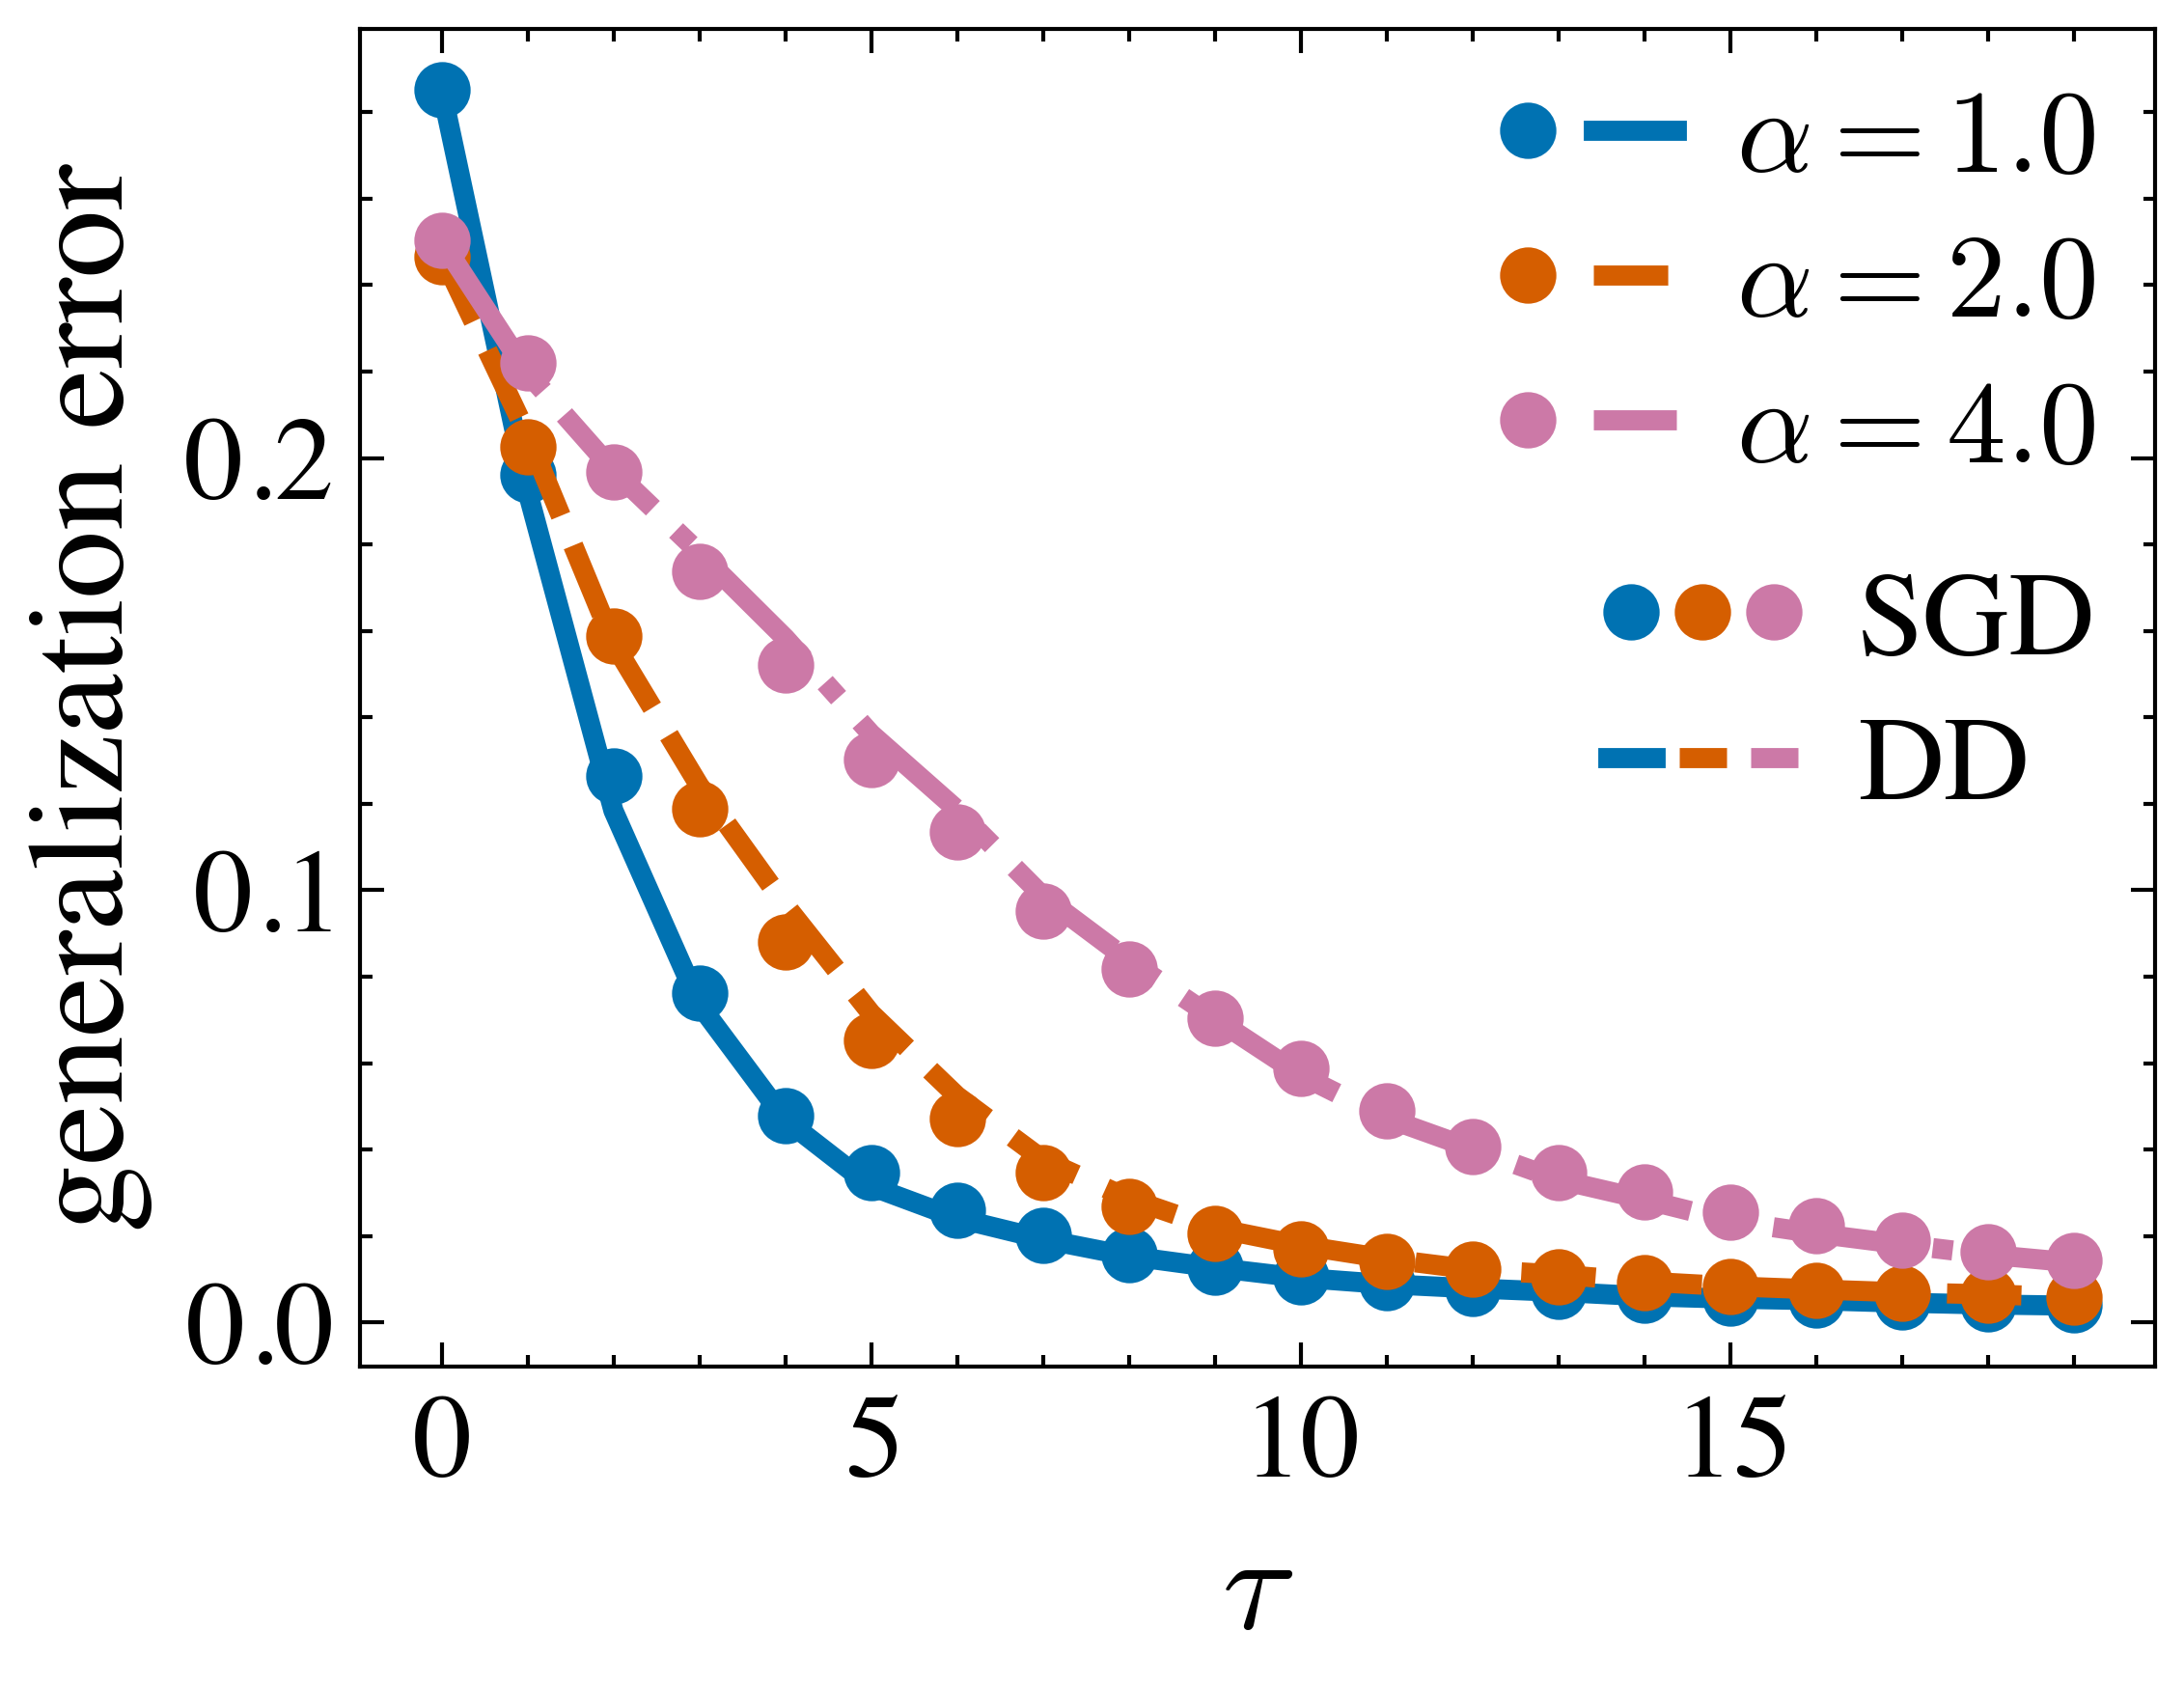

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.legend_handler import HandlerTuple
from tqdm import tqdm

# ---------------------------------------------------------
# 1. Setup
# ---------------------------------------------------------
n = 500
tau = 20.0
steps = int(tau * n)

eta = 1.0

def sigma(x):
    return np.maximum(x, 0)


def sigma_prime(x):
    return (x > 0).astype(float)

def teacher_func(z):
    return sigma(z) # ReLU teacher


alpha_values = [1.0, 2.0, 4.0]

sgd_plots = [None for _ in range(len(alpha_values))]
equivalent_plots = [None for _ in range(len(alpha_values))]

plt.figure(figsize=(4, 3))

for i, alpha in enumerate(alpha_values):
    k = int(alpha * n)
    lr_a = lr_f = eta / k

    rng = np.random.default_rng(42)

    xi = rng.normal(0, 1, n)
    xi /= np.linalg.norm(xi)
    F_init = rng.normal(0, 1 / np.sqrt(n), (k, n))
    a_init = rng.normal(0, 1, k)

    # ---------------------------------------------------------
    # Test set (fixed)
    # ---------------------------------------------------------
    test_size = 5000
    z0_test = rng.normal(0, 1, test_size)
    g_test = rng.normal(0, 1, (test_size, n))
    g_test -= np.outer(g_test @ xi, xi)  # project off xi
    x_test = np.outer(z0_test, xi) + g_test
    y_test = teacher_func(z0_test)

    def compute_loss_full(F, a):
        h = x_test @ F.T
        y_hat = (sigma(h) @ a) / k
        return 0.5 * np.mean((y_hat - y_test) ** 2)

    # ---------------------------------------------------------
    # 2. Run SGD (reference)
    # ---------------------------------------------------------
    print("Running SGD...")
    F_sgd = F_init.copy()
    a_sgd = a_init.copy()
    loss_sgd = []

    for t in tqdm(range(steps)):
        z0 = rng.normal()
        g = rng.normal(0, 1, n)
        g -= np.dot(g, xi) * xi
        x = z0 * xi + g

        h = F_sgd @ x
        e = (np.dot(a_sgd, sigma(h)) / k) - teacher_func(z0)
        v = e * a_sgd * sigma_prime(h)

        a_sgd -= lr_a * e * sigma(h)
        F_sgd -= lr_f * np.outer(v, x)

        if t % 500 == 0:
            loss_sgd.append(compute_loss_full(F_sgd, a_sgd))

    # ---------------------------------------------------------
    # 3. Run Decomposed Dynamics (complement drift = exact conditional mean of the SGD increment)
    # ---------------------------------------------------------
    print("Running Decomposed Dynamics (exact drift)...")
    F_ms = F_init.copy()
    a_ms = a_init.copy()
    loss_ms = []

    ghost_size = 512

    for t in tqdm(range(steps)):
        z0 = rng.normal()

        # --- Ghost batch over g | z0 ---
        g_g = rng.normal(0, 1, (ghost_size, n))
        g_g -= np.outer(g_g @ xi, xi)
        x_g = np.outer(np.ones(ghost_size), z0 * xi) + g_g

        h_g = x_g @ F_ms.T  # (B,k)
        y_hat_g = (sigma(h_g) @ a_ms) / k
        e_g = y_hat_g - teacher_func(z0)  # (B,)
        v_g = e_g[:, None] * a_ms[None, :] * sigma_prime(h_g)  # (B,k)

        # --- a drift (conditional expectation over g) ---
        grad_a = np.mean(e_g[:, None] * sigma(h_g), axis=0)  # (k,)
        a_ms -= lr_a * grad_a

        # --- decompose F into signal + bulk ---
        m_curr = F_ms @ xi  # (k,)
        F_perp = F_ms - np.outer(m_curr, xi)  # (k,n)

        # --- signal drift for m ---
        mu_v = np.mean(v_g, axis=0)  # (k,)
        m_new = m_curr - lr_f * mu_v * z0

        # --- complement drift: exact conditional mean of the SGD increment given z0 ---
        # (estimated by the ghost-batch average of v g^T, with g_g projected off xi)
        drift = (v_g.T @ g_g) / ghost_size  # (k,n)
        F_perp = F_perp - lr_f * drift

        # --- spike/noise injection with covariance (lr_f^2 * E[v v^T]) ⊗ P_perp ---
        noise_basis = rng.normal(0, 1, (ghost_size, n))
        noise_basis -= np.outer(noise_basis @ xi, xi)
        zeta = (lr_f / np.sqrt(ghost_size)) * (v_g.T @ noise_basis)  # (k,n)

        # recombine
        F_ms = np.outer(m_new, xi) + F_perp + zeta

        if t % 500 == 0:
            loss_ms.append(compute_loss_full(F_ms, a_ms))

    # ---------------------------------------------------------
    # 4. Plot
    # ---------------------------------------------------------
    time_axis = np.arange(len(loss_sgd)) * 500 / n

    (sgd_plots[i],) = plt.plot(
        time_axis,
        loss_sgd,
        color=colors[i],
        linestyle="None",
        marker="o",
        label="SGD (" + str(eta) + ")",
    )
    (equivalent_plots[i],) = plt.plot(
        time_axis,
        loss_ms,
        color=colors[i],
        linestyle=line_styles[i],
        linewidth=2.5,
    )

plt.xlabel(r"$\tau$")
plt.ylabel("generalization error")
plt.xticks([0, 5, 10, 15])
# plt.yscale("log")

legend1 = plt.legend(
    [
        (sgd_plots[0], sgd_plots[1], sgd_plots[2]),
        (
            equivalent_plots[0],
            equivalent_plots[1],
            equivalent_plots[2],
        ),
    ],
    [r"SGD", r"DD"],
    loc="center right",
    handler_map={tuple: HandlerTuple(ndivide=None)},
    handlelength=1.6, handletextpad=0.5, labelspacing=0.3, borderaxespad=0.3, borderpad=0.2,
)

legend2 = plt.legend(
    [
        (sgd_plots[0], equivalent_plots[0]),
        (sgd_plots[1], equivalent_plots[1]),
        (sgd_plots[2], equivalent_plots[2]),
    ],
    [
        fr"$\alpha={alpha_values[0]}$",
        fr"$\alpha={alpha_values[1]}$",
        fr"$\alpha={alpha_values[2]}$",
    ],
    loc=1,
    handler_map={tuple: HandlerTuple(ndivide=None)},
    handlelength=1.6, handletextpad=0.5, labelspacing=0.3, borderaxespad=0.3, borderpad=0.2,
)
plt.gca().add_artist(legend1)
plt.show()

Running SGD...
Running Decomposed Dynamics (exact drift)...
Running SGD...
Running Decomposed Dynamics (exact drift)...
Running SGD...
Running Decomposed Dynamics (exact drift)...


100%|██████████| 10000/10000 [03:47<00:00, 44.02it/s]


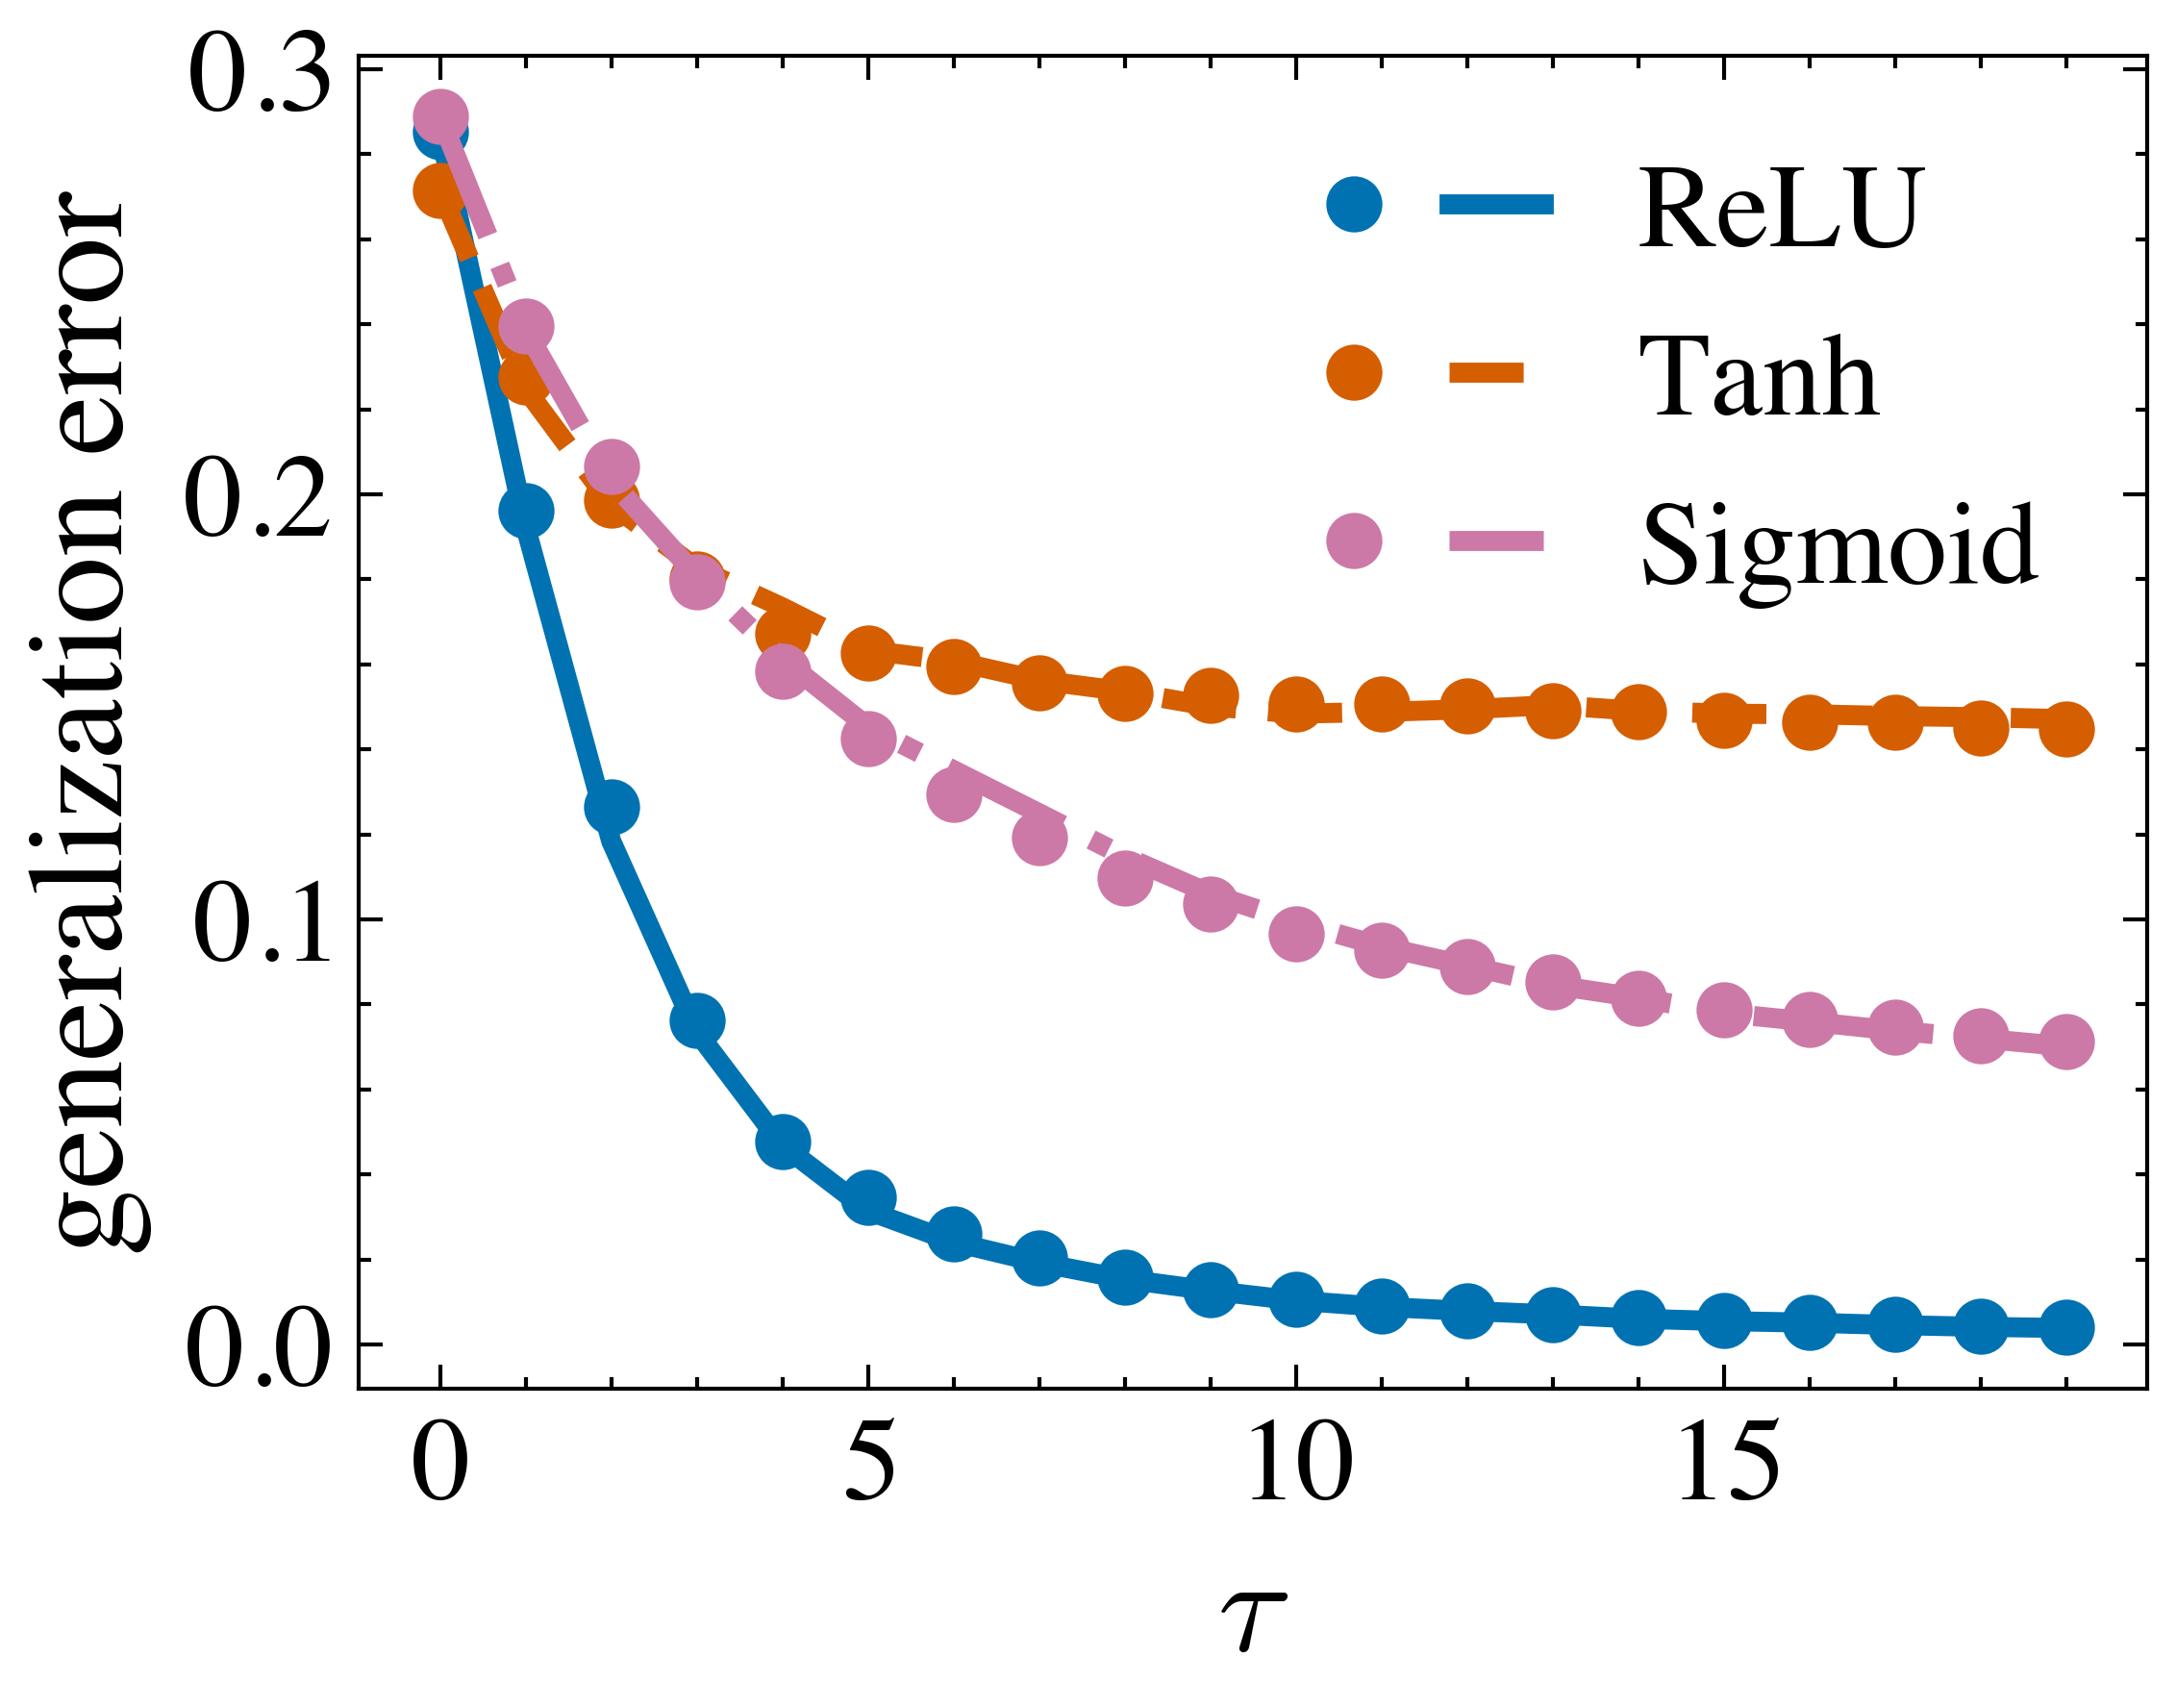

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.legend_handler import HandlerTuple
from tqdm import tqdm

# ---------------------------------------------------------
# 1. Setup
# ---------------------------------------------------------
n = 500
alpha = 1.0
k = int(alpha * n)
tau = 20.0
steps = int(tau * n)

eta = 1.0
lr_a = lr_f = eta / k

def relu(x):
    return np.maximum(x, 0)


def relu_prime(x):
    return (x > 0).astype(float)

def tanh(x):
    return np.tanh(x)

def tanh_prime(x):
    return 1.0 - np.tanh(x) ** 2

def sigmoid(x):
    return 1.0 / (1.0 + np.exp(-x))

def sigmoid_prime(x):
    s = sigmoid(x)
    return s * (1 - s)


def teacher_func(z):
    return relu(z)


sigmas = [(relu, relu_prime), (tanh, tanh_prime), (sigmoid, sigmoid_prime)]

sgd_plots = [None for _ in range(len(sigmas))]
equivalent_plots = [None for _ in range(len(sigmas))]

plt.figure(figsize=(4, 3))

for i, (sigma, sigma_prime) in enumerate(sigmas):
    rng = np.random.default_rng(42)

    xi = rng.normal(0, 1, n)
    xi /= np.linalg.norm(xi)
    F_init = rng.normal(0, 1 / np.sqrt(n), (k, n))
    a_init = rng.normal(0, 1, k)

    # ---------------------------------------------------------
    # Test set (fixed)
    # ---------------------------------------------------------
    test_size = 5000
    z0_test = rng.normal(0, 1, test_size)
    g_test = rng.normal(0, 1, (test_size, n))
    g_test -= np.outer(g_test @ xi, xi)  # project off xi
    x_test = np.outer(z0_test, xi) + g_test
    y_test = teacher_func(z0_test)

    def compute_loss_full(F, a):
        h = x_test @ F.T
        y_hat = (sigma(h) @ a) / k
        return 0.5 * np.mean((y_hat - y_test) ** 2)

    # ---------------------------------------------------------
    # 2. Run SGD (reference)
    # ---------------------------------------------------------
    print("Running SGD...")
    F_sgd = F_init.copy()
    a_sgd = a_init.copy()
    loss_sgd = []

    for t in tqdm(range(steps)):
        z0 = rng.normal()
        g = rng.normal(0, 1, n)
        g -= np.dot(g, xi) * xi
        x = z0 * xi + g

        h = F_sgd @ x
        e = (np.dot(a_sgd, sigma(h)) / k) - teacher_func(z0)
        v = e * a_sgd * sigma_prime(h)

        a_sgd -= lr_a * e * sigma(h)
        F_sgd -= lr_f * np.outer(v, x)

        if t % 500 == 0:
            loss_sgd.append(compute_loss_full(F_sgd, a_sgd))

    # ---------------------------------------------------------
    # 3. Run Decomposed Dynamics (complement drift = exact conditional mean of the SGD increment)
    # ---------------------------------------------------------
    print("Running Decomposed Dynamics (exact drift)...")
    F_ms = F_init.copy()
    a_ms = a_init.copy()
    loss_ms = []

    ghost_size = 512

    for t in tqdm(range(steps)):
        z0 = rng.normal()

        # --- Ghost batch over g | z0 ---
        g_g = rng.normal(0, 1, (ghost_size, n))
        g_g -= np.outer(g_g @ xi, xi)
        x_g = np.outer(np.ones(ghost_size), z0 * xi) + g_g

        h_g = x_g @ F_ms.T  # (B,k)
        y_hat_g = (sigma(h_g) @ a_ms) / k
        e_g = y_hat_g - teacher_func(z0)  # (B,)
        v_g = e_g[:, None] * a_ms[None, :] * sigma_prime(h_g)  # (B,k)

        # --- a drift (conditional expectation over g) ---
        grad_a = np.mean(e_g[:, None] * sigma(h_g), axis=0)  # (k,)
        a_ms -= lr_a * grad_a

        # --- decompose F into signal + bulk ---
        m_curr = F_ms @ xi  # (k,)
        F_perp = F_ms - np.outer(m_curr, xi)  # (k,n)

        # --- signal drift for m ---
        mu_v = np.mean(v_g, axis=0)  # (k,)
        m_new = m_curr - lr_f * mu_v * z0

        # --- complement drift: exact conditional mean of the SGD increment given z0 ---
        # (estimated by the ghost-batch average of v g^T, with g_g projected off xi)
        drift = (v_g.T @ g_g) / ghost_size  # (k,n)
        F_perp = F_perp - lr_f * drift

        # --- spike/noise injection with covariance (lr_f^2 * E[v v^T]) ⊗ P_perp ---
        noise_basis = rng.normal(0, 1, (ghost_size, n))
        noise_basis -= np.outer(noise_basis @ xi, xi)
        zeta = (lr_f / np.sqrt(ghost_size)) * (v_g.T @ noise_basis)  # (k,n)

        # recombine
        F_ms = np.outer(m_new, xi) + F_perp + zeta

        if t % 500 == 0:
            loss_ms.append(compute_loss_full(F_ms, a_ms))

    # ---------------------------------------------------------
    # 4. Plot
    # ---------------------------------------------------------
    time_axis = np.arange(len(loss_sgd)) * 500 / n

    (sgd_plots[i],) = plt.plot(
        time_axis,
        loss_sgd,
        color=colors[i],
        linestyle="None",
        marker="o",
        label="SGD (" + str(eta) + ")",
    )
    (equivalent_plots[i],) = plt.plot(
        time_axis,
        loss_ms,
        color=colors[i],
        linestyle=line_styles[i],
        linewidth=2.5,
    )

plt.xlabel(r"$\tau$")
plt.ylabel("generalization error")
plt.xticks([0, 5, 10, 15])

legend2 = plt.legend(
    [
        (sgd_plots[0], equivalent_plots[0]),
        (sgd_plots[1], equivalent_plots[1]),
        (sgd_plots[2], equivalent_plots[2]),
    ],
    [
        r"ReLU",
        r"Tanh",
        r"Sigmoid",
    ],
    loc=1,
    handler_map={tuple: HandlerTuple(ndivide=None)},
)
plt.show()